In [1]:
import random

In [2]:
# =========================================================
# COSTO DE UNA RUTA
# =========================================================

def calcular_longitud(ruta, distancias):
    total = 0.0

    for i in range(len(ruta) - 1):
        total += distancias[ruta[i]][ruta[i + 1]]

    return total

In [3]:
# =========================================================
# PRIMERA RUTA
# Sirve para obtener una estimación inicial razonable
# =========================================================

def vecino_mas_cercano(distancias, inicio=0):
    n = len(distancias)

    ruta = [inicio]
    pendientes = set(range(n))
    pendientes.remove(inicio)

    while pendientes:
        actual = ruta[-1]

        siguiente = min(
            pendientes,
            key=lambda ciudad: distancias[actual][ciudad]
        )

        ruta.append(siguiente)
        pendientes.remove(siguiente)

    ruta.append(inicio)

    return ruta

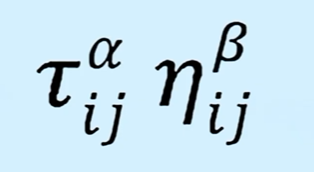

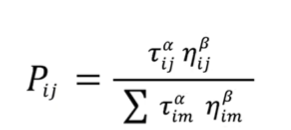

In [4]:
# =========================================================
# CONSTRUCCION DE RUTA
#
# Usa una idea de ACS:
#
# q <= q0  -> explotación
# q > q0   -> exploración probabilística
#
# Además realiza actualización LOCAL de feromonas.
# =========================================================

def construir_ruta(
    distancias,
    feromonas,
    alfa,
    beta,
    q0,
    xi,
    tau0,
    rng
):

    n = len(distancias)

    inicio = rng.randrange(n)

    ruta = [inicio]

    pendientes = list(range(n))
    pendientes.remove(inicio)

    while pendientes:

        actual = ruta[-1]

        pesos = []

        for ciudad in pendientes:

            tau = feromonas[actual][ciudad]

            distancia = distancias[actual][ciudad]

            # Evitar división entre cero
            eta = 1.0 / max(distancia, 1e-12)

            peso = (
                (tau ** alfa)
                *
                (eta ** beta)
            )

            pesos.append(peso)

        # ==============================================
        # ACS: explotación vs exploración
        # ==============================================

        q = rng.random()

        if q <= q0:

            # EXPLOTACIÓN:
            # elegir directamente la mejor alternativa

            indice = max(
                range(len(pesos)),
                key=lambda i: pesos[i]
            )

            siguiente = pendientes[indice]

        else:

            # EXPLORACIÓN:
            # ruleta probabilística

            siguiente = rng.choices(
                pendientes,
                weights=pesos,
                k=1
            )[0]

        ruta.append(siguiente)
        pendientes.remove(siguiente)

        # ==============================================
        # ACTUALIZACIÓN LOCAL DE ACS
        # ==============================================

        feromonas[actual][siguiente] = (
            (1 - xi) * feromonas[actual][siguiente]
            +
            xi * tau0
        )

        # TSP simétrico
        feromonas[siguiente][actual] = \
            feromonas[actual][siguiente]

    # volver al origen
    ruta.append(inicio)

    return ruta



In [5]:
# =========================================================
# 2-OPT
# Mejora localmente una ruta encontrada por las hormigas
# =========================================================

def dos_opt(ruta, distancias):
    ruta = ruta.copy()

    mejora = True

    while mejora:
        mejora = False

        # No tocamos el primer/último nodo porque son el mismo
        for i in range(1, len(ruta) - 2):

            for j in range(i + 1, len(ruta) - 1):

                a = ruta[i - 1]
                b = ruta[i]

                c = ruta[j]
                d = ruta[j + 1]

                costo_actual = (
                    distancias[a][b]
                    + distancias[c][d]
                )

                costo_nuevo = (
                    distancias[a][c]
                    + distancias[b][d]
                )

                # Si invertir este segmento mejora la ruta
                if costo_nuevo < costo_actual:
                    ruta[i:j + 1] = reversed(ruta[i:j + 1])

                    mejora = True
                    break

            if mejora:
                break

    return ruta

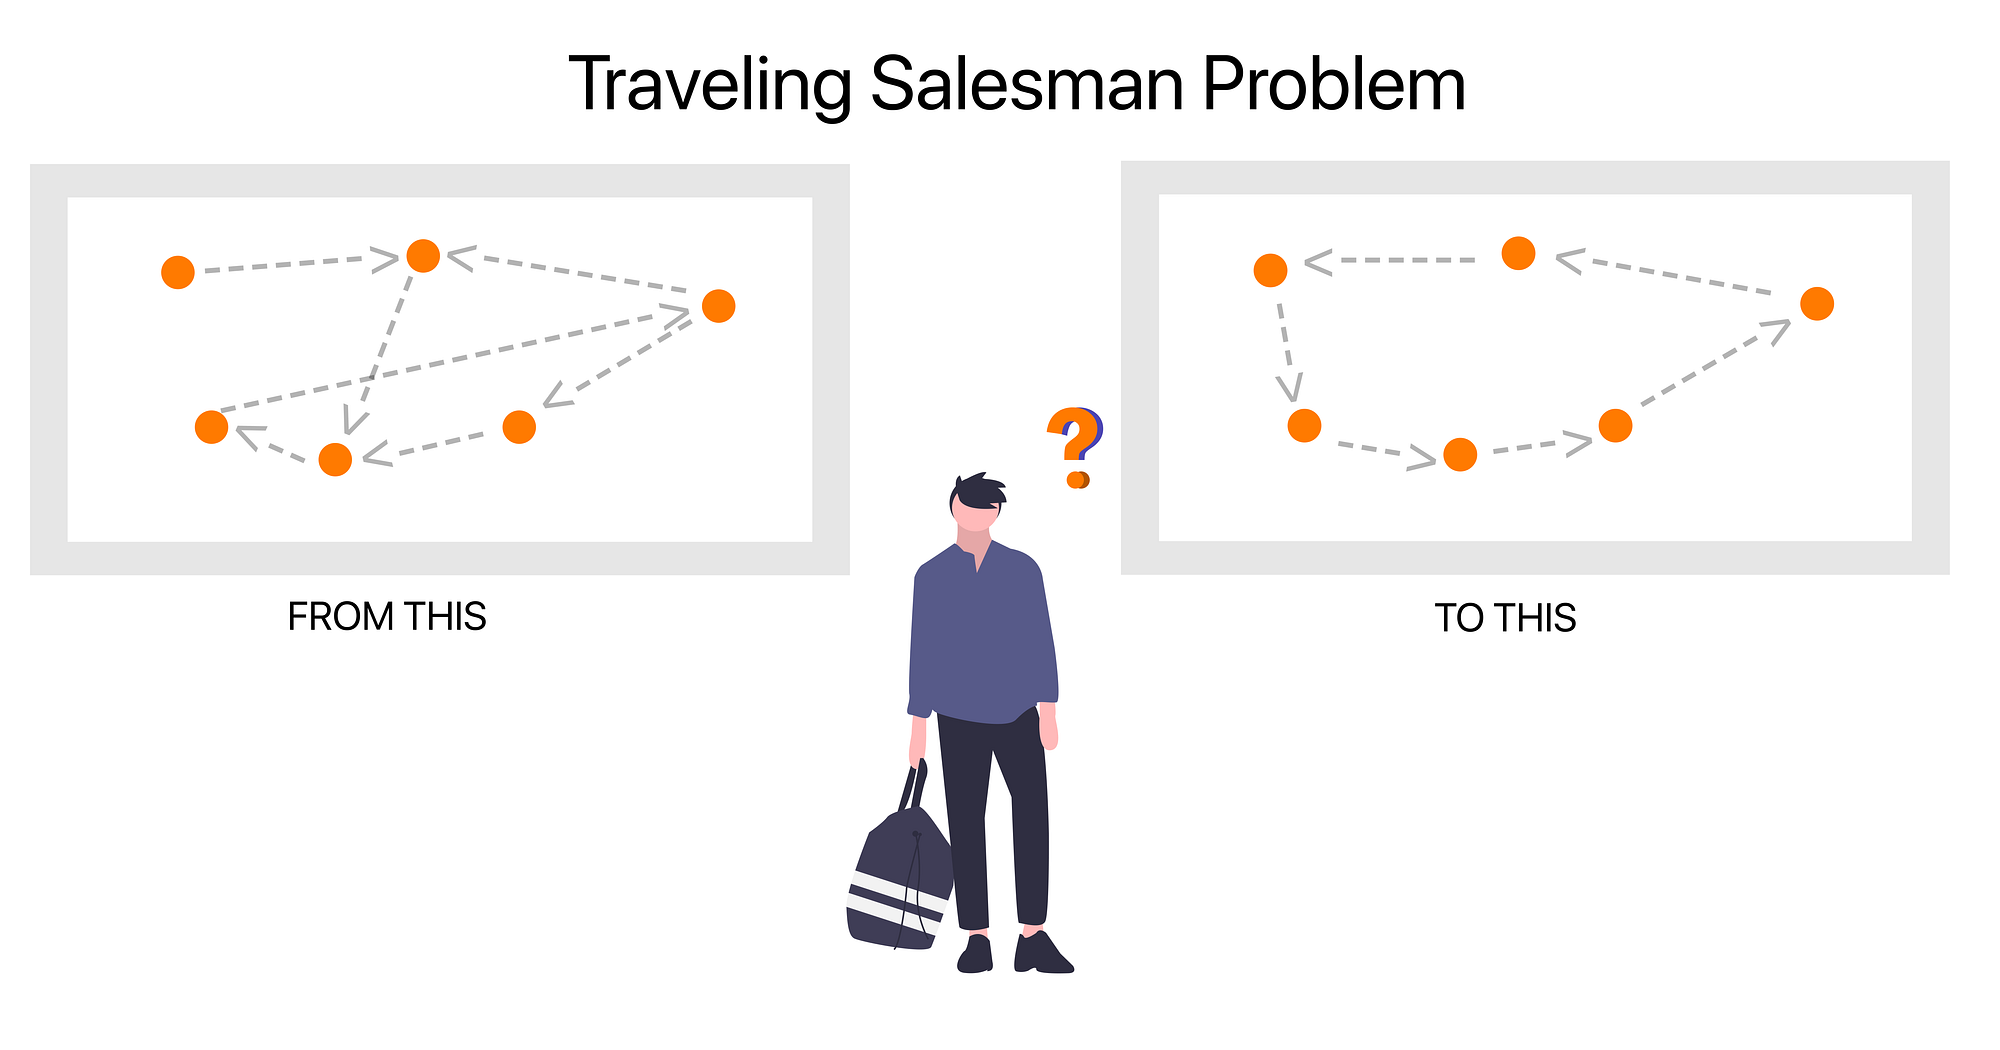




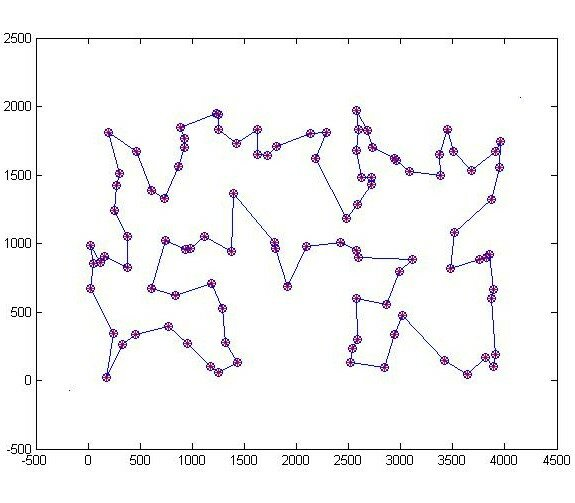

In [6]:
# =========================================================
# ACO
# =========================================================

def aco(
    distancias,
    hormigas=30,
    iteraciones=200,

    # evaporación global
    evaporacion=0.20,

    # actualización local ACS
    xi=0.10,

    # probabilidad inicial/final de explotación
    q0_inicio=0.65,
    q0_fin=0.95,

    # probabilidad de aplicar búsqueda local
    prob_2opt=0.30,

    # iteraciones sin mejorar antes de reiniciar
    limite_estancamiento=30,

    semilla=42
):

    n = len(distancias)

    rng = random.Random(semilla)

    # =====================================================
    # 1. ESTIMACIÓN INICIAL
    # =====================================================

    ruta_nn = vecino_mas_cercano(distancias)

    longitud_nn = calcular_longitud(
        ruta_nn,
        distancias
    )

    # Feromona inicial estilo ACS
    tau0 = 1.0 / (n * longitud_nn)

    # =====================================================
    # 2. MATRIZ DE FEROMONAS
    # =====================================================

    feromonas = []

    for i in range(n):

        fila = []

        for j in range(n):

            if i == j:
                fila.append(0.0)

            else:
                fila.append(tau0)

        feromonas.append(fila)

    # =====================================================
    # MEJOR SOLUCIÓN GLOBAL
    # =====================================================

    mejor_ruta = ruta_nn.copy()
    mejor_longitud = longitud_nn

    historial = []

    sin_mejorar = 0

    # =====================================================
    # ITERACIONES
    # =====================================================

    for iteracion in range(iteraciones):

        progreso = iteracion / max(iteraciones - 1, 1)

        # =================================================
        # PARÁMETROS ADAPTATIVOS
        #
        # Al inicio:
        # más exploración
        #
        # Al final:
        # más explotación de feromonas
        # =================================================

        alfa = 0.8 + 1.2 * progreso

        beta = 4.0 - 1.5 * progreso

        q0 = (
            q0_inicio
            +
            (q0_fin - q0_inicio) * progreso
        )

        soluciones = []

        hubo_mejora = False

        # =================================================
        # CONSTRUIR SOLUCIONES
        # =================================================

        for _ in range(hormigas):

            ruta = construir_ruta(
                distancias,
                feromonas,
                alfa,
                beta,
                q0,
                xi,
                tau0,
                rng
            )

            # =============================================
            # BÚSQUEDA LOCAL
            # =============================================

            if rng.random() < prob_2opt:
                ruta = dos_opt(
                    ruta,
                    distancias
                )

            longitud = calcular_longitud(
                ruta,
                distancias
            )

            soluciones.append(
                (longitud, ruta)
            )

            # =============================================
            # MEJOR GLOBAL
            # =============================================

            if longitud < mejor_longitud:

                mejor_longitud = longitud

                mejor_ruta = ruta.copy()

                hubo_mejora = True

        # =================================================
        # MEJOR DE ESTA ITERACIÓN
        # =================================================

        soluciones.sort(
            key=lambda x: x[0]
        )

        mejor_iteracion_longitud, mejor_iteracion_ruta = \
            soluciones[0]

        # =================================================
        # EVAPORACIÓN GLOBAL
        # =================================================

        for i in range(n):

            for j in range(n):

                if i != j:

                    feromonas[i][j] *= (
                        1.0 - evaporacion
                    )

        # =================================================
        # MMAS
        #
        # SOLO reforzamos la mejor solución global
        # =================================================

        deposito = 1.0 / mejor_longitud

        for k in range(len(mejor_ruta) - 1):

            i = mejor_ruta[k]
            j = mejor_ruta[k + 1]

            feromonas[i][j] += deposito
            feromonas[j][i] += deposito

        # =================================================
        # LIMITES MAX-MIN
        # =================================================

        tau_max = (
            1.0
            /
            (
                evaporacion
                *
                mejor_longitud
            )
        )

        tau_min = tau_max / (2.0 * n)

        for i in range(n):

            for j in range(n):

                if i != j:

                    feromonas[i][j] = max(
                        tau_min,
                        min(
                            tau_max,
                            feromonas[i][j]
                        )
                    )

        # =================================================
        # DETECCIÓN DE ESTANCAMIENTO
        # =================================================

        if hubo_mejora:

            sin_mejorar = 0

        else:

            sin_mejorar += 1

        # Si llevamos demasiado sin mejorar:
        # aumentar nuevamente la diversidad

        if sin_mejorar >= limite_estancamiento:

            for i in range(n):

                for j in range(n):

                    if i != j:
                        feromonas[i][j] = tau_max

            sin_mejorar = 0

        historial.append(
            mejor_longitud
        )

    return (
        mejor_ruta,
        mejor_longitud,
        historial
    )

In [7]:
# Instalar tsplib95 en Google Colab
!pip install -q tsplib95

import urllib.request
import tsplib95


# =====================================================
# DESCARGAR AUTOMÁTICAMENTE EL ARCHIVO TSP
# =====================================================

url = (
    "https://raw.githubusercontent.com/"
    "coin-or/jorlib/master/"
    "jorlib-core/src/test/resources/tspLib/tsp/"
    "kroA100.tsp"
)

archivo = "kroA100.tsp"

urllib.request.urlretrieve(url, archivo)

print("Archivo descargado:", archivo)


# =====================================================
# CARGAR EL PROBLEMA
# =====================================================

problem = tsplib95.load(archivo)

print("Nombre:", problem.name)
print("Dimensión:", problem.dimension)
print("Tipo de distancia:", problem.edge_weight_type)


# =====================================================
# OBTENER LOS NODOS
# =====================================================

nodes = list(problem.get_nodes())

print("Cantidad de nodos:", len(nodes))


# =====================================================
# CREAR MATRIZ DE DISTANCIAS
# =====================================================

matrix = [
    [
        problem.get_weight(i, j)
        for j in nodes
    ]
    for i in nodes
]

print("Tamaño de la matriz:")
print(len(matrix), "x", len(matrix[0]))


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Archivo descargado: kroA100.tsp
Nombre: kroA100
Dimensión: 100
Tipo de distancia: EUC_2D
Cantidad de nodos: 100
Tamaño de la matriz:
100 x 100


In [ ]:
nombres = [str(n) for n in nodes]

distancias = matrix

ruta, longitud, historial = aco(distancias, hormigas=5, iteraciones=200)

etiquetas = [nombres[i] for i in ruta]

print("Mejor ruta encontrada:", " -> ".join(etiquetas))
print(f"Distancia total: {longitud:.2f}")
print(
        "Mejor distancia en las primeras 5 iteraciones:",
        historial[:5]
    )

Mejor ruta encontrada: 59 -> 17 -> 15 -> 11 -> 32 -> 45 -> 91 -> 98 -> 23 -> 77 -> 60 -> 62 -> 35 -> 86 -> 27 -> 12 -> 20 -> 57 -> 9 -> 7 -> 55 -> 83 -> 34 -> 29 -> 46 -> 43 -> 3 -> 14 -> 71 -> 41 -> 100 -> 48 -> 30 -> 39 -> 96 -> 78 -> 52 -> 5 -> 37 -> 33 -> 76 -> 13 -> 95 -> 82 -> 85 -> 68 -> 73 -> 50 -> 44 -> 2 -> 54 -> 40 -> 64 -> 69 -> 81 -> 25 -> 87 -> 51 -> 61 -> 58 -> 67 -> 28 -> 93 -> 47 -> 1 -> 63 -> 6 -> 49 -> 90 -> 19 -> 75 -> 92 -> 8 -> 42 -> 89 -> 31 -> 80 -> 56 -> 97 -> 4 -> 65 -> 26 -> 66 -> 70 -> 22 -> 94 -> 16 -> 88 -> 53 -> 79 -> 18 -> 24 -> 38 -> 99 -> 36 -> 84 -> 10 -> 72 -> 21 -> 74 -> 59
Distancia total: 21282.00
Mejor distancia en las primeras 5 iteraciones: [21839.0, 21450.0, 21379.0, 21282.0, 21282.0]


In [9]:
problem = tsplib95.load("u2319.tsp")

print(problem.name)
print(problem.dimension)
print(problem.edge_weight_type)
nodes = list(problem.get_nodes())

matrix = [
    [
        problem.get_weight(i, j)
        for j in nodes
    ]
    for i in nodes
]

len(matrix)


u2319
2319
EUC_2D


2319

In [10]:
nombres = [str(n) for n in nodes]

distancias = matrix

ruta, longitud, historial = aco(distancias, hormigas=10, iteraciones=100)

etiquetas = [nombres[i] for i in ruta]

print("Mejor ruta encontrada:", " -> ".join(etiquetas))
print(f"Distancia total: {longitud:.2f}")
print(
        "Mejor distancia en las primeras 5 iteraciones:",
        historial[:5])

KeyboardInterrupt: 